In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
from sklearn.linear_model import LinearRegression
import seaborn as sns
housepredict = pd.read_csv("house_prices_practice.csv")

housepredict.head()

housepredict.info()
housepredict.describe()
housepredict.isna().sum()
housepredict.duplicated().sum()





<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Id            300 non-null    int64
 1   OverallQual   300 non-null    int64
 2   GrLivArea     300 non-null    int64
 3   GarageCars    300 non-null    int64
 4   TotalBsmtSF   300 non-null    int64
 5   YearBuilt     300 non-null    int64
 6   FullBath      300 non-null    int64
 7   BedroomAbvGr  300 non-null    int64
 8   LotArea       300 non-null    int64
 9   SalePrice     300 non-null    int64
dtypes: int64(10)
memory usage: 23.6 KB


np.int64(0)

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

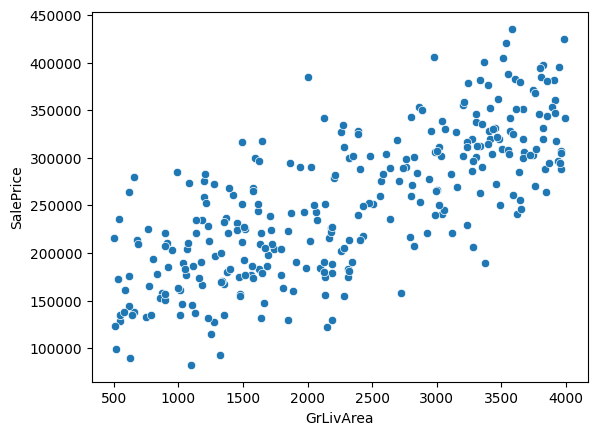

In [2]:
sns.scatterplot(
    data=housepredict,
    x="GrLivArea",
    y="SalePrice"
)

In [3]:
housepredict[
    [
        "OverallQual",
        "GrLivArea",
        "YearBuilt",
        "TotalBsmtSF",
        "GarageCars",
        "SalePrice"
    ]
].corr()

,OverallQual,GrLivArea,YearBuilt,TotalBsmtSF,GarageCars,SalePrice
OverallQual,1.000000,-0.116413,0.005990,0.008098,-0.017138,0.352899
GrLivArea,-0.116413,1.000000,0.032073,0.023471,0.056380,0.745095
YearBuilt,0.005990,0.032073,1.000000,-0.050187,-0.031599,0.222142
TotalBsmtSF,0.008098,0.023471,-0.050187,1.000000,0.051605,0.250178
GarageCars,-0.017138,0.056380,-0.031599,0.051605,1.000000,0.351321
SalePrice,0.352899,0.745095,0.222142,0.250178,0.351321,1.000000


In [4]:
X = housepredict[
    [
        "OverallQual",
        "GrLivArea",
        "YearBuilt",
        "TotalBsmtSF",
        "GarageCars",
        "FullBath",
        "BedroomAbvGr"
    ]
]

y = housepredict["SalePrice"]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [7]:
y_pred = model.predict(X_test)

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 10438.754799094411
MSE: 155062787.9838834
RMSE: 12452.42096878689
R2: 0.9726703004838797


In [9]:
housepredict.dtypes

Id              int64
OverallQual     int64
GrLivArea       int64
GarageCars      int64
TotalBsmtSF     int64
YearBuilt       int64
FullBath        int64
BedroomAbvGr    int64
LotArea         int64
SalePrice       int64
dtype: object

In [10]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(10))

   Actual      Predicted
0  224163  238265.115874
1  203881  190625.189237
2  380236  397820.077022
3  211664  223394.729886
4  122139  135412.301270
5  180067  180287.606473
6  275810  282979.235035
7  209025  204251.799372
8  213952  206624.377851
9  154885  171361.962353


In [11]:
housepredict["Expensive"] = (housepredict["SalePrice"] > housepredict["SalePrice"].median()).astype(int)

X = housepredict.drop(columns=["Id", "SalePrice", "Expensive"])
y = housepredict["Expensive"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667
Precision: 0.9666666666666667
Recall: 0.9666666666666667
F1 Score: 0.9666666666666667

Confusion Matrix:
[[29  1]
 [ 1 29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        30
           1       0.97      0.97      0.97        30

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



In [12]:
import joblib

joblib.dump(model, "linear_model.pkl")

['linear_model.pkl']

In [13]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

joblib.dump(linear_model, "linear_model.pkl")

['linear_model.pkl']

In [14]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train_scaled, y_train)

joblib.dump(logistic_model, "logistic_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [15]:
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


housepredict = pd.read_csv("house_prices_practice.csv")


housepredict["Expensive"] = (
    housepredict["SalePrice"] > housepredict["SalePrice"].median()
).astype(int)


features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr",
    "LotArea"
]


X = housepredict[features]
y = housepredict["Expensive"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree.fit(X_train, y_train)

dt_pred = decision_tree.predict(X_test)


random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)


print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1:", f1_score(y_test, dt_pred))


print("\nRandom Forest")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))

Decision Tree
Accuracy: 0.8333333333333334
Precision: 0.8571428571428571
Recall: 0.8
F1: 0.8275862068965517

Random Forest
Accuracy: 0.9
Precision: 0.9285714285714286
Recall: 0.8666666666666667
F1: 0.896551724137931


In [16]:

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


housepredict = pd.read_csv("house_prices_practice.csv")


housepredict["Expensive"] = (
    housepredict["SalePrice"] > housepredict["SalePrice"].median()
).astype(int)


features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr",
    "LotArea"
]


X = housepredict[features]

y = housepredict["Expensive"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


model = KNeighborsClassifier(
    n_neighbors=5
)


model.fit(
    X_train_scaled,
    y_train
)


y_pred = model.predict(
    X_test_scaled
)


print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))


print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred
    )
)


print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)

Accuracy: 0.8833333333333333
Precision: 0.9259259259259259
Recall: 0.8333333333333334
F1 Score: 0.8771929824561403

Confusion Matrix:
[[28  2]
 [ 5 25]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89        30
           1       0.93      0.83      0.88        30

    accuracy                           0.88        60
   macro avg       0.89      0.88      0.88        60
weighted avg       0.89      0.88      0.88        60



In [17]:


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score




# =========================================

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr",
    "LotArea"
]

X = housepredict[features]
y = housepredict["SalePrice"]


# =========================================
# 3. Train / Test Split
# =========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# =========================================
# 4. Feature Scaling
# =========================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# =========================================
# 5. Create KNN Regression Model
# =========================================

model = KNeighborsRegressor(
    n_neighbors=5
)


# =========================================
# 6. Train Model
# =========================================

model.fit(X_train_scaled, y_train)


# =========================================
# 7. Prediction
# =========================================

y_pred = model.predict(X_test_scaled)


# =========================================
# 8. Evaluation
# =========================================

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("KNN Regression Results")
print("----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


# =========================================
# 9. Predict New House
# =========================================

new_house = pd.DataFrame({
    "OverallQual": [7],
    "GrLivArea": [2000],
    "GarageCars": [2],
    "TotalBsmtSF": [1500],
    "YearBuilt": [2015],
    "FullBath": [2],
    "BedroomAbvGr": [3],
    "LotArea": [9000]
})


new_house_scaled = scaler.transform(new_house)

predicted_price = model.predict(new_house_scaled)

print("\nPredicted House Price:")
print(predicted_price[0])

KNN Regression Results
----------------------
MAE: 26682.95666666667
MSE: 1168176545.3353336
RMSE: 34178.59776724805
R2 Score: 0.7941097643032683

Predicted House Price:
322114.2
